# 3. Stage 2: Direct path and RF front-end

In a bi-static system, the receiver hears the transmitter directly. This is usually by far its strongest signal, so it sets the dynamic-range requirement.

## Mechanisms, and when each applies

Each is evaluated and either used or rejected, and the reason is recorded.

| Mechanism | Source | Applies when |
|---|---|---|
| Free space | P.525 | Always |
| Refraction, k-factor | P.453 | Always: sets the effective Earth radius |
| Spherical-Earth diffraction | P.526-16 sec. 3.2 | Clearance below about 0.55 of the first Fresnel radius (eq. 23) |
| Terrain diffraction (Bullington) | P.526-16 sec. 4.5 | A terrain profile is supplied |
| Atmospheric gases | P.676 | Over 0.1 dB on this path |
| Rain | P.838, P.530-19 sec. 2.4.1 | Rain rate set, and over 0.1 dB |
| Ground reflection (two-ray) | Fresnel reflection with P.527-class ground values | Clear path with a significant specular ray |
| Clear-air fading | P.530-19 sec. 2.3.1 | Over 5 km, $f \geq 15/d$ GHz, grazing line of sight, inclination to 37 mrad |
| Terminal clutter | P.2108-1 sec. 3.2 | Set by user; 0.5 to 67 GHz; path over 0.25 km |

Two details were corrected by reading the current texts, not relying on older formulas:

- P.526-16 eq. 17b is $F(X) = -20\log_{10}X - 5.6488X^{1.425}$, which is continuous with eq. 17a at $X=1.6$.
- P.530-19 eq. 7 is a newer fit with $d^{3.51}$ and $(f^2+13)^{0.447}$. Its geoclimatic factor K comes from a data grid that is not bundled here, so K is an input. **Set it for your site.** The default is only a starting value.

### Diffraction at any distance (P.526 sec. 3.2)

1. Past the marginal line-of-sight distance $d_{los} = \sqrt{2a_e}(\sqrt{h_1}+\sqrt{h_2})$, use the first-term residue formula.
2. Otherwise compare the clearance $h$ with $h_{req} = 0.552\sqrt{d_1 d_2 \lambda/d}$. If $h > h_{req}$, there is no loss.
3. Otherwise interpolate: $A = (1 - h/h_{req})\,A_h$, with $A_h$ found from a modified Earth radius that gives marginal line of sight.

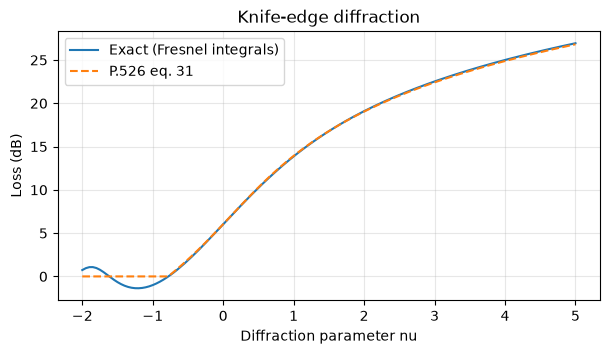

Loss at grazing incidence: 6.02 dB


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.propagation.diffraction import spherical_earth_loss_db, knife_edge_j_db, knife_edge_exact_db
from bistatic_lb.propagation.surface import GROUND_TYPES

nu = np.linspace(-2, 5, 141)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(nu, knife_edge_exact_db(nu), label="Exact (Fresnel integrals)")
ax.plot(nu, knife_edge_j_db(nu), "--", label="P.526 eq. 31")
ax.set(xlabel="Diffraction parameter nu", ylabel="Loss (dB)", title="Knife-edge diffraction"); ax.legend(); ax.grid(alpha=0.3); plt.show()
print(f"Loss at grazing incidence: {knife_edge_exact_db(0.0):.2f} dB")


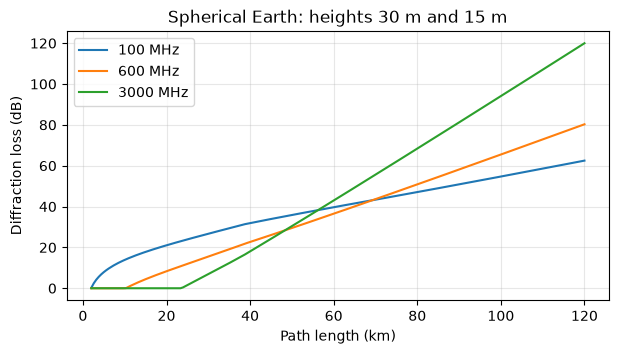

In [2]:
d = np.linspace(2, 120, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
for f in (100e6, 600e6, 3e9):
    ax.plot(d, [spherical_earth_loss_db(x, 30, 15, f, 8500, GROUND_TYPES["medium"]).loss_db for x in d], label=f"{f/1e6:.0f} MHz")
ax.set(xlabel="Path length (km)", ylabel="Diffraction loss (dB)", title="Spherical Earth: heights 30 m and 15 m"); ax.legend(); ax.grid(alpha=0.3); plt.show()


Low frequencies have a larger Fresnel zone, so they need more clearance and suffer diffraction well inside the horizon, but lose less far beyond it.

## This design's direct path

In [3]:
s = Scenario.from_yaml(Path("../scenarios/dvbt_uhf.yaml" if Path.cwd().name == "notebooks" else "scenarios/dvbt_uhf.yaml"))
r = run_link_budget(s)
d = r.direct
for c in d.terms.contributions:
    print(f"{c.name:46s} {c.value:8.2f} {c.unit:3s} used: {str(c.applicable):5s}  {c.reason}")
print()
print(f"Per element: maximum {d.element_maximum_dbm:.1f}, nominal {d.element_nominal_dbm:.1f}, minimum {d.element_minimum_dbm:.1f} dBm")
print(d.maximum_note)


Free-space loss                                  114.03 dB  used: True   Always applies: the basic spreading of the wave.
Refraction (k-factor)                              1.34     used: True   Refractivity gradient -40 N/km gives an effective Earth radius of 8549 km.
Diffraction: Spherical Earth                       8.30 dB  used: True   Clearance 15.1 m against the 26.6 m needed for zero loss: line of sight with too little clearance. The ray grazes or crosses the surface, so it applies.
Atmospheric gases                                  0.11 dB  used: True   Specific attenuation 0.0054 dB/km over this path is significant.
Rain attenuation                                   0.00 dB  used: False  Disabled: the rain rate is zero.
Ground reflection (two-ray)                        0.00 dB  used: False  Rejected: the diffraction model already accounts for the ground on this path.
Clear-air multipath fade                           0.00 dB  used: False  Rejected: 0.60 GHz is below the P.53

## Three levels, because they answer three different questions

- **Maximum** sizes the ADC and limiter. It assumes no rain, an in-phase ground ray, and, by default, ducting, which can lift a blocked path to near free space. It is an engineering bound, not a statistic.
- **Nominal** is the typical operating level.
- **Minimum** includes rain and fading at the chosen time percentage, and sizes the AGC range.

## The order of operations decides the requirement

With one ADC per element, the direct signal reaches each ADC **before any beamforming**. A digital spatial null is therefore no help for ADC dynamic range. It helps only after conversion. Suppression is counted in two separate groups:

| Before the ADC (protects the ADC) | After the ADC (protects the detector) |
|---|---|
| Analog subarray null, RF canceller | Digital beamforming null, digital canceller such as ECA |

## Noise above quantization, and the gain window

With $B$ the signal bandwidth, $f_s$ the sample rate, $N_{ENOB}$ the effective bits and $P_{FS}$ the full-scale power, the in-band quantization noise is

$$Q = P_{FS} - (6.02 N_{ENOB}+1.76) - 10\log_{10}\frac{f_s}{2B}$$

and the instantaneous range is $D = P_{FS} - Q$. With $N = N_0 + 10\log_{10}B$ the in-band noise and $P_{\max} - S_{\mathrm{pre}}$ the strongest direct signal after analog suppression, both at the antenna terminals, the gain limits are

$$G_{\min} = Q - N,\qquad G_{\max} = P_{FS} - \mathrm{PAPR} - H - (P_{\max} - S_{\mathrm{pre}})$$

At $G_{\min}$ noise equals quantization, which costs 3 dB. At $G_{\max}$ the strongest peak just reaches full scale. Noise above quantization is therefore **not a design choice**. At the highest usable gain it is fixed by three levels:

$$M_{\max} = G_{\max} - G_{\min} = D - (\mathrm{PAPR} + H) - \underbrace{(P_{\max} - S_{\mathrm{pre}} - N)}_{\text{direct-to-noise ratio}}$$

The window width equals $M_{\max}$. If it is negative, noise stays under quantization at any gain, and the gap is what extra bits or analog suppression must supply. Quantization costs $L = 10\log_{10}(1 + 10^{-M/10})$ at the noise-over-quantization ratio $M$ the AGC actually reaches.

**How many bits?** No fixed $M$ target is assumed. The detection margin, plus the loss already counted in it, is the margin an ideal ADC would leave, $L_{\mathrm{allow}}$. The loss at the maximum direct level must fit inside it, so $M \ge -10\log_{10}(10^{L_{\mathrm{allow}}/10} - 1)$, and each effective bit adds 6.02 dB to $M$.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Effective bits 13.5, instantaneous range 84.0 dB
Back-off 13.5 dB, direct-to-noise at the ADC input 54.1 dB
Noise above quantization: 16.4 dB at best, 11.2 dB in operation
Gain window 21.9 to 38.3 dB, configured 33.1 dB
Detection leaves 3.0 dB for quantization, so 14.2 ADC bits are needed


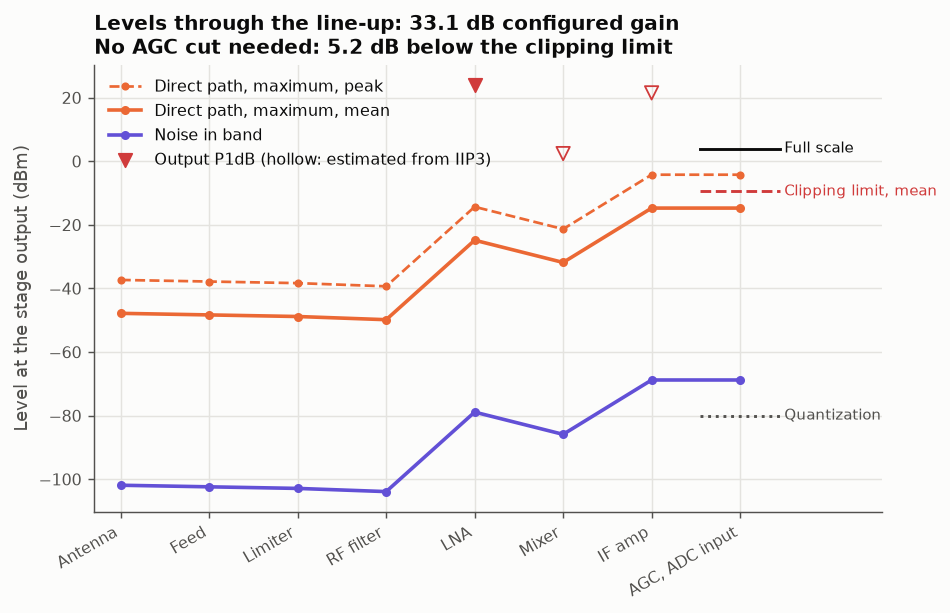

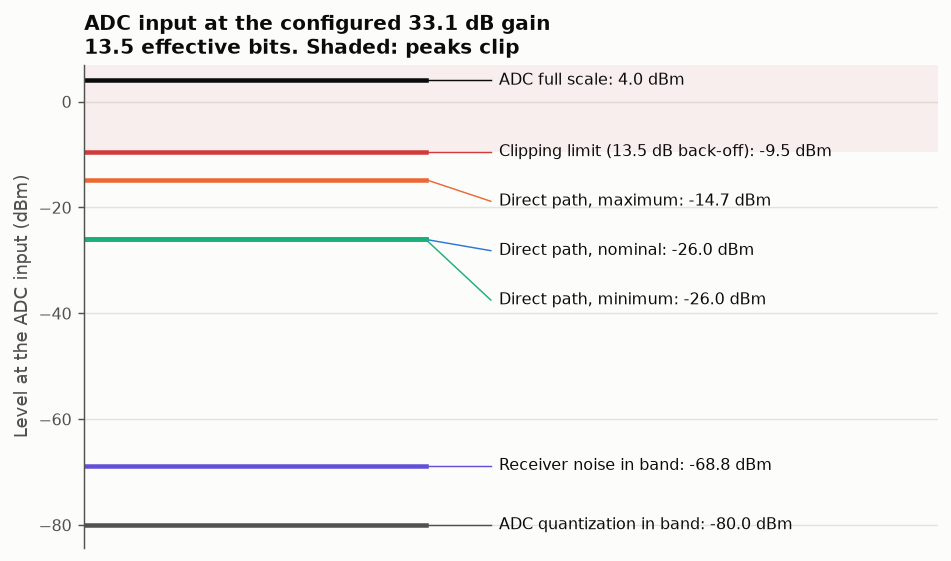

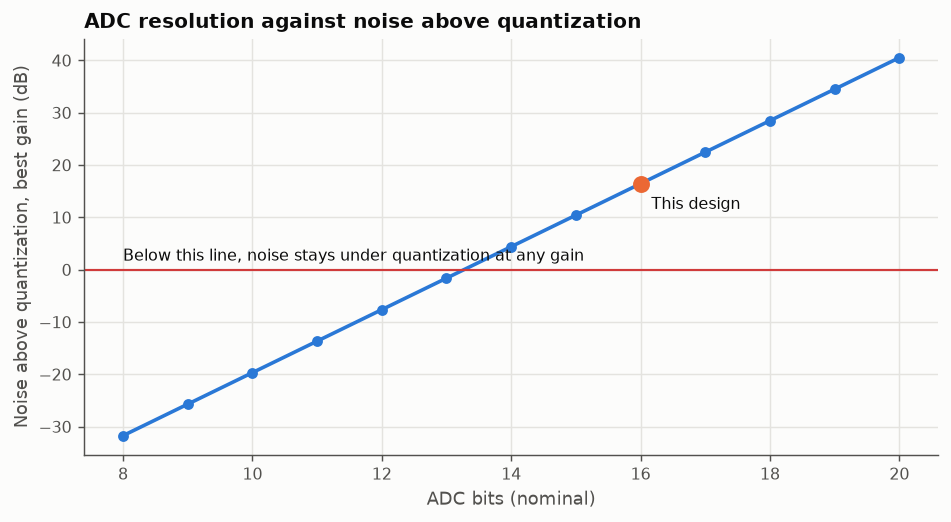

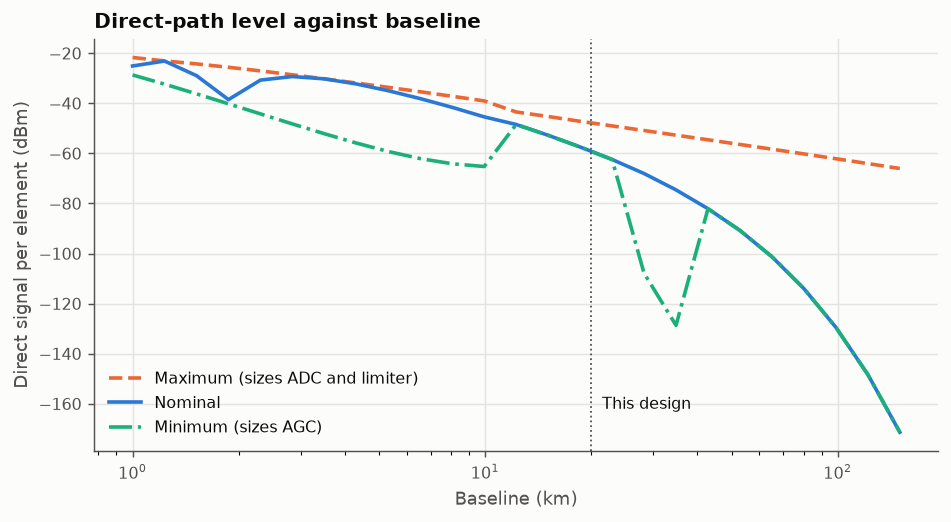

In [4]:
f = r.frontend
print(f"Effective bits {f.effective_bits:.1f}, instantaneous range {f.instantaneous_dynamic_range_db:.1f} dB")
print(f"Back-off {f.clipping_backoff_db:.1f} dB, direct-to-noise at the ADC input {f.direct_to_noise_at_adc_db:.1f} dB")
print(f"Noise above quantization: {f.noise_over_quantization_db:.1f} dB at best, {f.noise_over_quantization_nominal_db:.1f} dB in operation")
print(f"Gain window {f.gain_min_db:.1f} to {f.gain_max_db:.1f} dB, configured {f.configured_gain_db:.1f} dB")
print(f"Detection leaves {f.allowed_quantization_loss_db:.1f} dB for quantization, so {f.required_adc_bits:.1f} ADC bits are needed")
plots.lineup_levels(r); plots.dynamic_range_ladder(r); plots.gain_window_vs_bits(r); plots.direct_levels_vs_baseline(s); plt.show()


## Derived front-end requirements

In [5]:
for q in f.requirements:
    state = {True: "Met", False: "NOT MET", None: "-"}[q.met]
    print(f"{q.item:36s} need: {q.required:38s} have: {q.configured:42s} {state}")
    print(f"    {q.rationale}")


Noise above quantization             need: Computed                               have: 16.4 dB at best; 11.2 dB in operation      -
    Instantaneous range 84.0 dB at 19 MS/s, minus 13.5 dB back-off, minus a 54.1 dB direct-to-noise ratio at the ADC input. Costs 0.32 dB of sensitivity at the nominal direct level and 0.32 dB at the maximum.
Receiver gain window                 need: Non-empty window                       have: 21.9 to 38.3 dB (16.4 dB wide)             Met
    From the gain that lifts noise to the quantization level, up to the gain at which the strongest signal clips.
ADC resolution                       need: 14.2 bits (11.7 effective)             have: 16 bits (13.5 effective)                   Met
    An ideal ADC would leave 3.0 dB of detection margin. At the maximum direct signal, quantization must cost no more than that, so noise must sit at least 0.1 dB above quantization; this design gives 11.2 dB (0.32 dB loss).
Configured gain vs window            need: Inside

## Pulsed waveforms: gated gain

DVB-T carries the direct signal all the time, so one AGC gain holds for all time and the target pays the direct signal's back-off. A pulsed waveform is different: the direct pulse is present for one pulse width per repetition interval. A gated receiver drops the gain while the pulse is present and restores it while listening, so noise at the ADC rises back above quantization once the pulse has passed.

The cost is a blind time: the pulse width plus the gain switch's settling time. Echoes within that much extra path are eclipsed. Stages ahead of the switch (LNA, mixer, IF) still see the full pulse.

Below, the pulsed LFM example at a 2 km baseline, where the direct pulse forces a large gain cut.

continuous: pulse gain 24.1 dB, listening gain -, noise over quantization 2.2 dB, loss 2.03 dB, detection margin +1.02 dB


gated     : pulse gain 24.1 dB, listening gain 41.3 dB, noise over quantization 10.6 dB, loss 0.36 dB, detection margin +2.69 dB


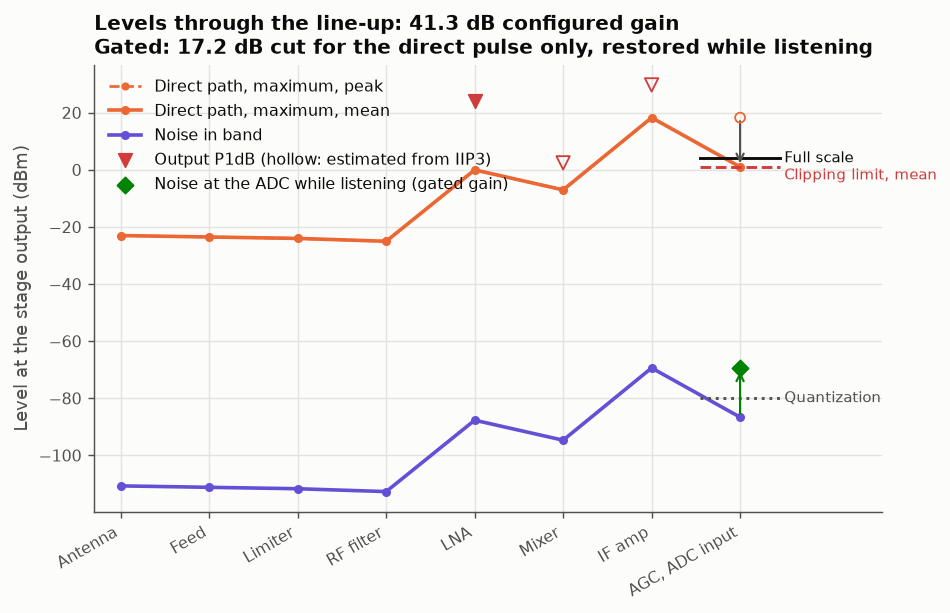

In [6]:
p = Scenario.from_yaml(Path("../scenarios/pulsed_lfm_uhf.yaml" if Path.cwd().name == "notebooks" else "scenarios/pulsed_lfm_uhf.yaml")).with_value("geometry.baseline_km", 2.0)
for mode in ("continuous", "gated"):
    x = run_link_budget(p.with_value("frontend.gain_control", mode)); g = x.frontend
    listening = "-" if g.listening_gain_db is None else f"{g.listening_gain_db:.1f} dB"
    print(f"{mode:10s}: pulse gain {g.pulse_gain_db:.1f} dB, listening gain {listening}, noise over quantization {g.noise_over_quantization_nominal_db:.1f} dB, "
          f"loss {g.sensitivity_loss_db:.2f} dB, detection margin {x.detection.margin_db:+.2f} dB")
plots.lineup_levels(x); plt.show()

## Trade-off: what closes a shortfall?

This confirms the point above in numbers. Adding a digital null changes the signal at the detector but not the gain window, while an analog null widens it dB for dB.

In [7]:
digital = run_link_budget(s.with_value("array.null_on_transmitter", True))
none = run_link_budget(s.with_value("array.null_on_transmitter", False))
analog = run_link_budget(s.with_value("array.digitization", "analog_subarray"))
print(f"{'Option':28s}{'Gain window dB':>16s}{'Direct at output dBm':>22s}")
for name, x in (("No null", none), ("Digital null", digital), ("Analog subarray null", analog)):
    print(f"{name:28s}{x.frontend.gain_window_db:16.1f}{x.direct.output_nominal_dbm:22.1f}")


Option                        Gain window dB  Direct at output dBm
No null                                 16.4                 -60.2
Digital null                            16.4                 -88.3
Analog subarray null                    41.4                 -88.3
